# CelebA pretrained versus local epoch-15 box inpainting

This notebook compares the repository's official pretrained CelebA OT-flow checkpoint with the local `model_15.pt` checkpoint on the same held-out CelebA image. Both models receive identical preprocessing, masks, noisy observations, PnP-Flow hyperparameters, and random seeds.

The default mask sizes are 5, 10, 20, and 40 pixels in the 128 x 128 model input. The 40 x 40 case matches the repository's built-in CelebA box-inpainting size. The solver defaults to the original-author behavior: observation noise is enabled and known pixels are enforced through the soft data term rather than hard-clamped after every step.

In [1]:
from pathlib import Path
import csv
import json
import os
import re
import time

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch
from torchvision.transforms import v2

repo_root = Path.cwd().resolve()
if not (repo_root / 'pnpflow').is_dir():
    repo_root = repo_root.parent
if not (repo_root / 'pnpflow').is_dir():
    raise RuntimeError('Open this notebook from the PnP-Flow repository or its notebooks directory.')
os.chdir(repo_root)
from pnpflow.utils import define_model

OFFICIAL_CHECKPOINT = repo_root / 'model/celeba/ot/model_final.pt'
LOCAL_RUN_NAME = '20260622_134957_celeba_ot'
LOCAL_CHECKPOINT = repo_root / 'model/celeba/ot' / LOCAL_RUN_NAME / 'model_15.pt'
LOCAL_LOSS_PATH = repo_root / 'results/celeba/ot' / LOCAL_RUN_NAME / 'loss_training.txt'
PARTITION_CSV = repo_root / 'data/celeba/list_eval_partition.csv'
IMAGE_ROOT = repo_root / 'data/celeba/img_align_celeba'
nested_image_root = IMAGE_ROOT / 'img_align_celeba'
if nested_image_root.is_dir():
    IMAGE_ROOT = nested_image_root

# Image selection. Set IMAGE_OVERRIDE to an absolute path or a path relative to IMAGE_ROOT.
IMAGE_OVERRIDE = None
TEST_IMAGE_INDEX = 5
with PARTITION_CSV.open(newline='', encoding='utf-8') as handle:
    test_names = [row['image_id'] for row in csv.DictReader(handle) if int(row['partition']) == 2]
if IMAGE_OVERRIDE is None:
    if not 0 <= TEST_IMAGE_INDEX < len(test_names):
        raise IndexError(f'TEST_IMAGE_INDEX={TEST_IMAGE_INDEX}; valid range is 0:{len(test_names)}')
    IMAGE_PATH = IMAGE_ROOT / test_names[TEST_IMAGE_INDEX]
    IMAGE_SELECTION = f'CelebA test index {TEST_IMAGE_INDEX}'
else:
    requested = Path(IMAGE_OVERRIDE).expanduser()
    IMAGE_PATH = requested if requested.is_absolute() else IMAGE_ROOT / requested
    IMAGE_PATH = IMAGE_PATH.resolve()
    IMAGE_SELECTION = 'explicit IMAGE_OVERRIDE'

MODEL_SIZE = 128
MASK_SIZES = (5, 10, 20, 40)
MASK_CENTER_XY = (80, 64)
STEPS_PNP = 100
NUM_SAMPLES = 5
LR_PNP = 1.0
NOISE_STD = 0.05
ALPHA = 0.5
ADD_OBSERVATION_NOISE = True
HARD_KNOWN_PIXEL_CONSISTENCY = False
USE_ORIGINAL_INITIALIZATION = True
BASE_SEED = 0
USE_MULTI_GPU = True

OUTPUT_DIR = (repo_root / 'results/celeba/ot/pretrained_vs_local_epoch15_box_inpainting' /
              IMAGE_PATH.stem / f'center_x{MASK_CENTER_XY[0]}_y{MASK_CENTER_XY[1]}')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for path in (OFFICIAL_CHECKPOINT, LOCAL_CHECKPOINT, PARTITION_CSV, IMAGE_PATH):
    assert path.is_file(), f'Required file not found: {path}'
print(f'Image selection: {IMAGE_SELECTION}')
print(f'Image: {IMAGE_PATH}')
print(f'Official checkpoint: {OFFICIAL_CHECKPOINT}')
print(f'Local checkpoint: {LOCAL_CHECKPOINT}')
print(f'Masks: {MASK_SIZES}; center (X, Y): {MASK_CENTER_XY}')
print(f'Output directory: {OUTPUT_DIR}')

/data2/marci/bselvaku/conda/envs/torchlearn/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Image selection: CelebA test index 5
Image: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/data/celeba/img_align_celeba/img_align_celeba/182643.jpg
Official checkpoint: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/model/celeba/ot/model_final.pt
Local checkpoint: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/model/celeba/ot/20260622_134957_celeba_ot/model_15.pt
Masks: (5, 10, 20, 40); center (X, Y): (80, 64)
Output directory: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/celeba/ot/pretrained_vs_local_epoch15_box_inpainting/182643/center_x80_y64


In [2]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
if device.type != 'cuda':
    raise RuntimeError('This comparison requires a CUDA GPU.')

class ModelArgs:
    model = 'ot'
    num_channels = 3
    dim_image = MODEL_SIZE

def load_model(checkpoint):
    instance, _ = define_model(ModelArgs())
    instance.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
    instance.to(device).eval()
    if USE_MULTI_GPU and torch.cuda.device_count() > 1:
        instance = torch.nn.DataParallel(
            instance, device_ids=list(range(torch.cuda.device_count())), output_device=0
        )
    return instance

official_model = load_model(OFFICIAL_CHECKPOINT)
local_model = load_model(LOCAL_CHECKPOINT)
print(f'Loaded both models on {torch.cuda.device_count()} visible GPU(s); primary device={device}')

Loaded both models on 4 visible GPU(s); primary device=cuda:0


/data2/marci/bselvaku/conda/envs/torchlearn/lib/python3.11/site-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


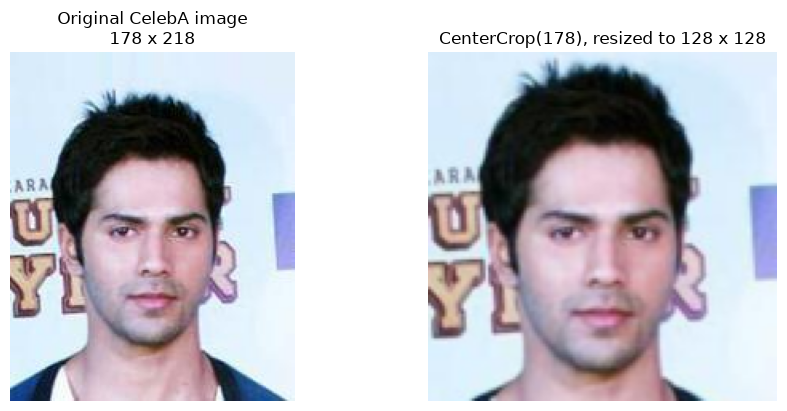

In [3]:
# Match pnpflow/dataloaders.py CelebA preprocessing exactly.
celeba_transform = v2.Compose([
    v2.CenterCrop(178),
    v2.Resize((MODEL_SIZE, MODEL_SIZE)),
    v2.ToTensor(),
    v2.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])
with Image.open(IMAGE_PATH) as image:
    original_rgb = image.convert('RGB').copy()
clean = celeba_transform(original_rgb).float()
if clean.shape != (3, MODEL_SIZE, MODEL_SIZE):
    raise ValueError(f'Expected 3 x 128 x 128 input, got {tuple(clean.shape)}')
clean_np = clean.numpy()

fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
axes[0].imshow(original_rgb)
axes[0].set_title(f'Original CelebA image\n{original_rgb.size[0]} x {original_rgb.size[1]}')
axes[1].imshow(np.transpose((clean_np + 1) / 2, (1, 2, 0)).clip(0, 1))
axes[1].set_title('CenterCrop(178), resized to 128 x 128')
for ax in axes:
    ax.axis('off')
plt.show()

In [4]:
def missing_mask_at_center(size, center_xy):
    if not 0 < size < MODEL_SIZE:
        raise ValueError(f'Mask size must be between 1 and {MODEL_SIZE - 1}, got {size}.')
    center_x, center_y = map(int, center_xy)
    top, left = center_y - size // 2, center_x - size // 2
    bottom, right = top + size, left + size
    if not (0 <= top < bottom <= MODEL_SIZE and 0 <= left < right <= MODEL_SIZE):
        raise ValueError(f'{size} x {size} mask centered at {center_xy} is outside the image.')
    missing = np.zeros((MODEL_SIZE, MODEL_SIZE), dtype=bool)
    missing[top:bottom, left:right] = True
    return missing, (top, left, bottom, right)

def make_observation(clean_image, missing_mask, seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    clean_tensor = torch.from_numpy(clean_image)[None].to(device=device, dtype=torch.float32)
    missing = torch.from_numpy(missing_mask.astype(np.float32))[None, None].to(device)
    known = 1.0 - missing
    observed = known * clean_tensor
    if ADD_OBSERVATION_NOISE:
        # The author evaluator adds Gaussian noise after applying H.
        observed = observed + torch.randn_like(observed) * NOISE_STD
    return clean_tensor, observed, known, missing

@torch.inference_mode()
def pnp_flow_inpaint(model, observed, known, missing, solver_seed):
    torch.manual_seed(solver_seed)
    torch.cuda.manual_seed_all(solver_seed)
    x = known.expand_as(observed).clone() if USE_ORIGINAL_INITIALIZATION else known * observed
    lr = (NOISE_STD ** 2) * LR_PNP
    start = time.perf_counter()
    for iteration in range(STEPS_PNP):
        t = torch.full((1,), iteration / STEPS_PNP, device=device)
        lr_t = lr * (1.0 - t).pow(ALPHA).view(1, 1, 1, 1)
        data_gradient = known * (known * x - observed) / (NOISE_STD ** 2)
        z = x - lr_t * data_gradient

        t_samples = t.expand(NUM_SAMPLES)
        t_view = t_samples.view(NUM_SAMPLES, 1, 1, 1)
        z_samples = z.expand(NUM_SAMPLES, -1, -1, -1)
        z_tilde = t_view * z_samples + (1.0 - t_view) * torch.randn_like(z_samples)
        velocity = model(z_tilde, t_samples)
        candidates = z_tilde + (1.0 - t_view) * velocity
        x_new = candidates.mean(dim=0, keepdim=True)
        x = known * observed + missing * x_new if HARD_KNOWN_PIXEL_CONSISTENCY else x_new
    torch.cuda.synchronize()
    return x[0].clamp(-1, 1).cpu().numpy(), time.perf_counter() - start

results = {}
for size in MASK_SIZES:
    missing_np, bounds = missing_mask_at_center(size, MASK_CENTER_XY)
    clean_tensor, observed, known, missing = make_observation(clean_np, missing_np, BASE_SEED + size)
    # Resetting to the same solver seed gives both priors the same stochastic draws.
    solver_seed = BASE_SEED + 1000 + size
    official_output, official_seconds = pnp_flow_inpaint(official_model, observed, known, missing, solver_seed)
    local_output, local_seconds = pnp_flow_inpaint(local_model, observed, known, missing, solver_seed)
    results[size] = {
        'bounds': bounds, 'missing': missing_np,
        'observed': (known * observed)[0].cpu().numpy(),
        'official': official_output, 'local_epoch15': local_output,
        'official_seconds': official_seconds, 'local_seconds': local_seconds,
    }
    print(f'{size} x {size}: official={official_seconds:.2f}s, local epoch 15={local_seconds:.2f}s')

5 x 5: official=17.22s, local epoch 15=15.53s
10 x 10: official=15.67s, local epoch 15=15.71s
20 x 20: official=15.89s, local epoch 15=15.74s
40 x 40: official=15.63s, local epoch 15=15.60s


In [5]:
def image_metrics(reference, estimate, missing):
    mask3 = np.broadcast_to(missing[None], reference.shape)
    missing_error = estimate[mask3] - reference[mask3]
    full_error = estimate - reference
    missing_mse = float(np.mean(missing_error ** 2))
    full_mse = float(np.mean(full_error ** 2))
    known_error = full_error[~mask3]
    return {
        'missing_psnr_0_1': float(10 * np.log10(1.0 / max(missing_mse / 4.0, 1e-12))),
        'missing_mae_normalized': float(np.mean(np.abs(missing_error))),
        'full_psnr_0_1': float(10 * np.log10(1.0 / max(full_mse / 4.0, 1e-12))),
        'known_mae_normalized': float(np.mean(np.abs(known_error))),
    }

summary = {
    'image': str(IMAGE_PATH), 'official_checkpoint': str(OFFICIAL_CHECKPOINT),
    'local_checkpoint': str(LOCAL_CHECKPOINT), 'mask_center_xy': list(MASK_CENTER_XY),
    'steps_pnp': STEPS_PNP, 'num_samples': NUM_SAMPLES,
    'noise_std': NOISE_STD, 'alpha': ALPHA,
    'add_observation_noise': ADD_OBSERVATION_NOISE,
    'hard_known_pixel_consistency': HARD_KNOWN_PIXEL_CONSISTENCY,
    'use_original_initialization': USE_ORIGINAL_INITIALIZATION, 'masks': {},
}
np.save(OUTPUT_DIR / 'clean_celeba_128_normalized_float32.npy', clean_np.astype(np.float32))
for size, item in results.items():
    official_metrics = image_metrics(clean_np, item['official'], item['missing'])
    local_metrics = image_metrics(clean_np, item['local_epoch15'], item['missing'])
    official_metrics['seconds'] = float(item['official_seconds'])
    local_metrics['seconds'] = float(item['local_seconds'])
    summary['masks'][str(size)] = {
        'bounds_top_left_bottom_right': list(map(int, item['bounds'])),
        'official_pretrained': official_metrics, 'local_epoch15': local_metrics,
    }
    np.save(OUTPUT_DIR / f'missing_mask_{size}x{size}_uint8.npy', item['missing'].astype(np.uint8))
    np.save(OUTPUT_DIR / f'observed_{size}x{size}_normalized_float32.npy', item['observed'].astype(np.float32))
    np.save(OUTPUT_DIR / f'official_reconstruction_{size}x{size}_normalized_float32.npy', item['official'].astype(np.float32))
    np.save(OUTPUT_DIR / f'local_epoch15_reconstruction_{size}x{size}_normalized_float32.npy', item['local_epoch15'].astype(np.float32))
    print(
        f'{size} x {size}: missing PSNR official={official_metrics["missing_psnr_0_1"]:.3f} dB; '
        f'local epoch15={local_metrics["missing_psnr_0_1"]:.3f} dB'
    )
with (OUTPUT_DIR / 'metrics.json').open('w', encoding='utf-8') as handle:
    json.dump(summary, handle, indent=2)
print(f'Saved arrays and metrics to: {OUTPUT_DIR}')

5 x 5: missing PSNR official=25.580 dB; local epoch15=24.776 dB
10 x 10: missing PSNR official=22.301 dB; local epoch15=21.009 dB
20 x 20: missing PSNR official=24.740 dB; local epoch15=20.772 dB
40 x 40: missing PSNR official=18.294 dB; local epoch15=19.033 dB
Saved arrays and metrics to: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/celeba/ot/pretrained_vs_local_epoch15_box_inpainting/182643/center_x80_y64


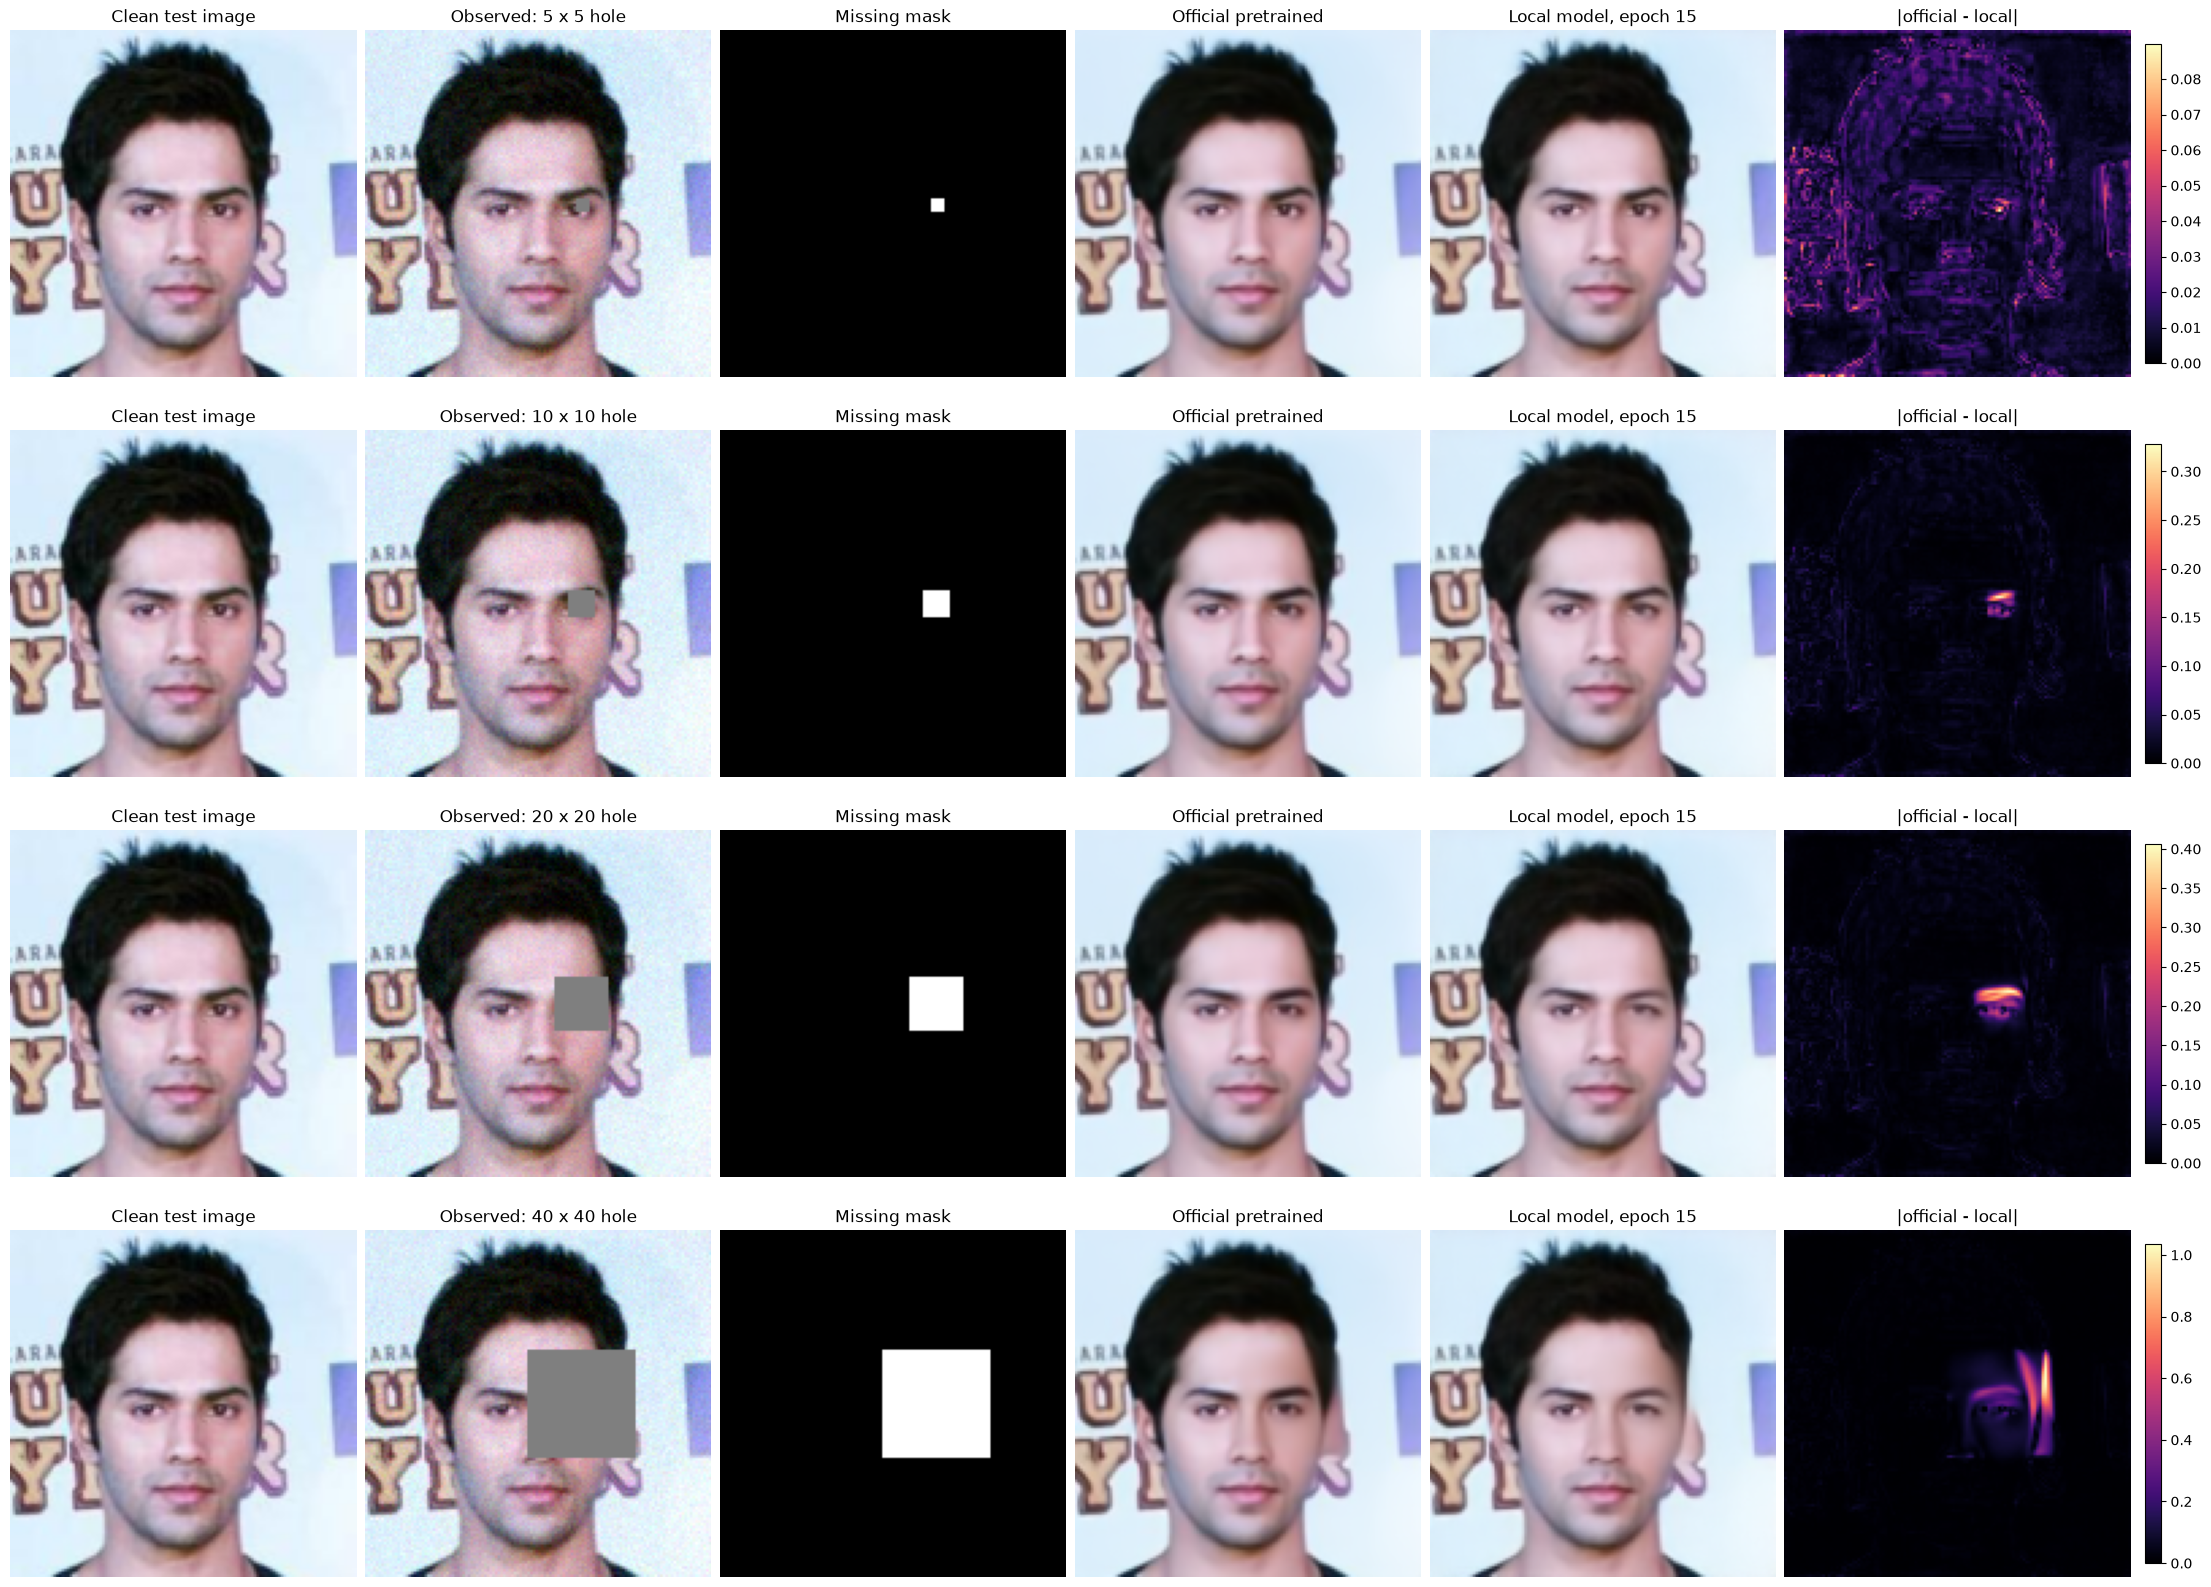

Saved: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/celeba/ot/pretrained_vs_local_epoch15_box_inpainting/182643/center_x80_y64/official_vs_local_epoch15_all_masks.png


In [6]:
def rgb_display(chw):
    return np.transpose((chw + 1.0) / 2.0, (1, 2, 0)).clip(0, 1)

fig, axes = plt.subplots(len(MASK_SIZES), 6, figsize=(22, 4 * len(MASK_SIZES)), constrained_layout=True)
for row, size in enumerate(MASK_SIZES):
    item = results[size]
    mask = item['missing']
    official_error = np.zeros((MODEL_SIZE, MODEL_SIZE), dtype=np.float32)
    local_error = np.zeros_like(official_error)
    official_error[mask] = np.mean(np.abs(item['official'] - clean_np), axis=0)[mask]
    local_error[mask] = np.mean(np.abs(item['local_epoch15'] - clean_np), axis=0)[mask]
    error_limit = max(float(official_error.max()), float(local_error.max()), 1e-6)

    axes[row, 0].imshow(rgb_display(clean_np)); axes[row, 0].set_title('Clean test image')
    axes[row, 1].imshow(rgb_display(item['observed'])); axes[row, 1].set_title(f'Observed: {size} x {size} hole')
    axes[row, 2].imshow(mask, cmap='gray', vmin=0, vmax=1); axes[row, 2].set_title('Missing mask')
    axes[row, 3].imshow(rgb_display(item['official'])); axes[row, 3].set_title('Official pretrained')
    axes[row, 4].imshow(rgb_display(item['local_epoch15'])); axes[row, 4].set_title('Local model, epoch 15')
    delta = np.mean(np.abs(item['official'] - item['local_epoch15']), axis=0)
    image = axes[row, 5].imshow(delta, cmap='magma', vmin=0, vmax=max(float(delta.max()), 1e-6))
    axes[row, 5].set_title('|official - local|')
    fig.colorbar(image, ax=axes[row, 5], fraction=0.046, pad=0.04)
    for ax in axes[row]:
        ax.axis('off')
comparison_path = OUTPUT_DIR / 'official_vs_local_epoch15_all_masks.png'
fig.savefig(comparison_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {comparison_path}')

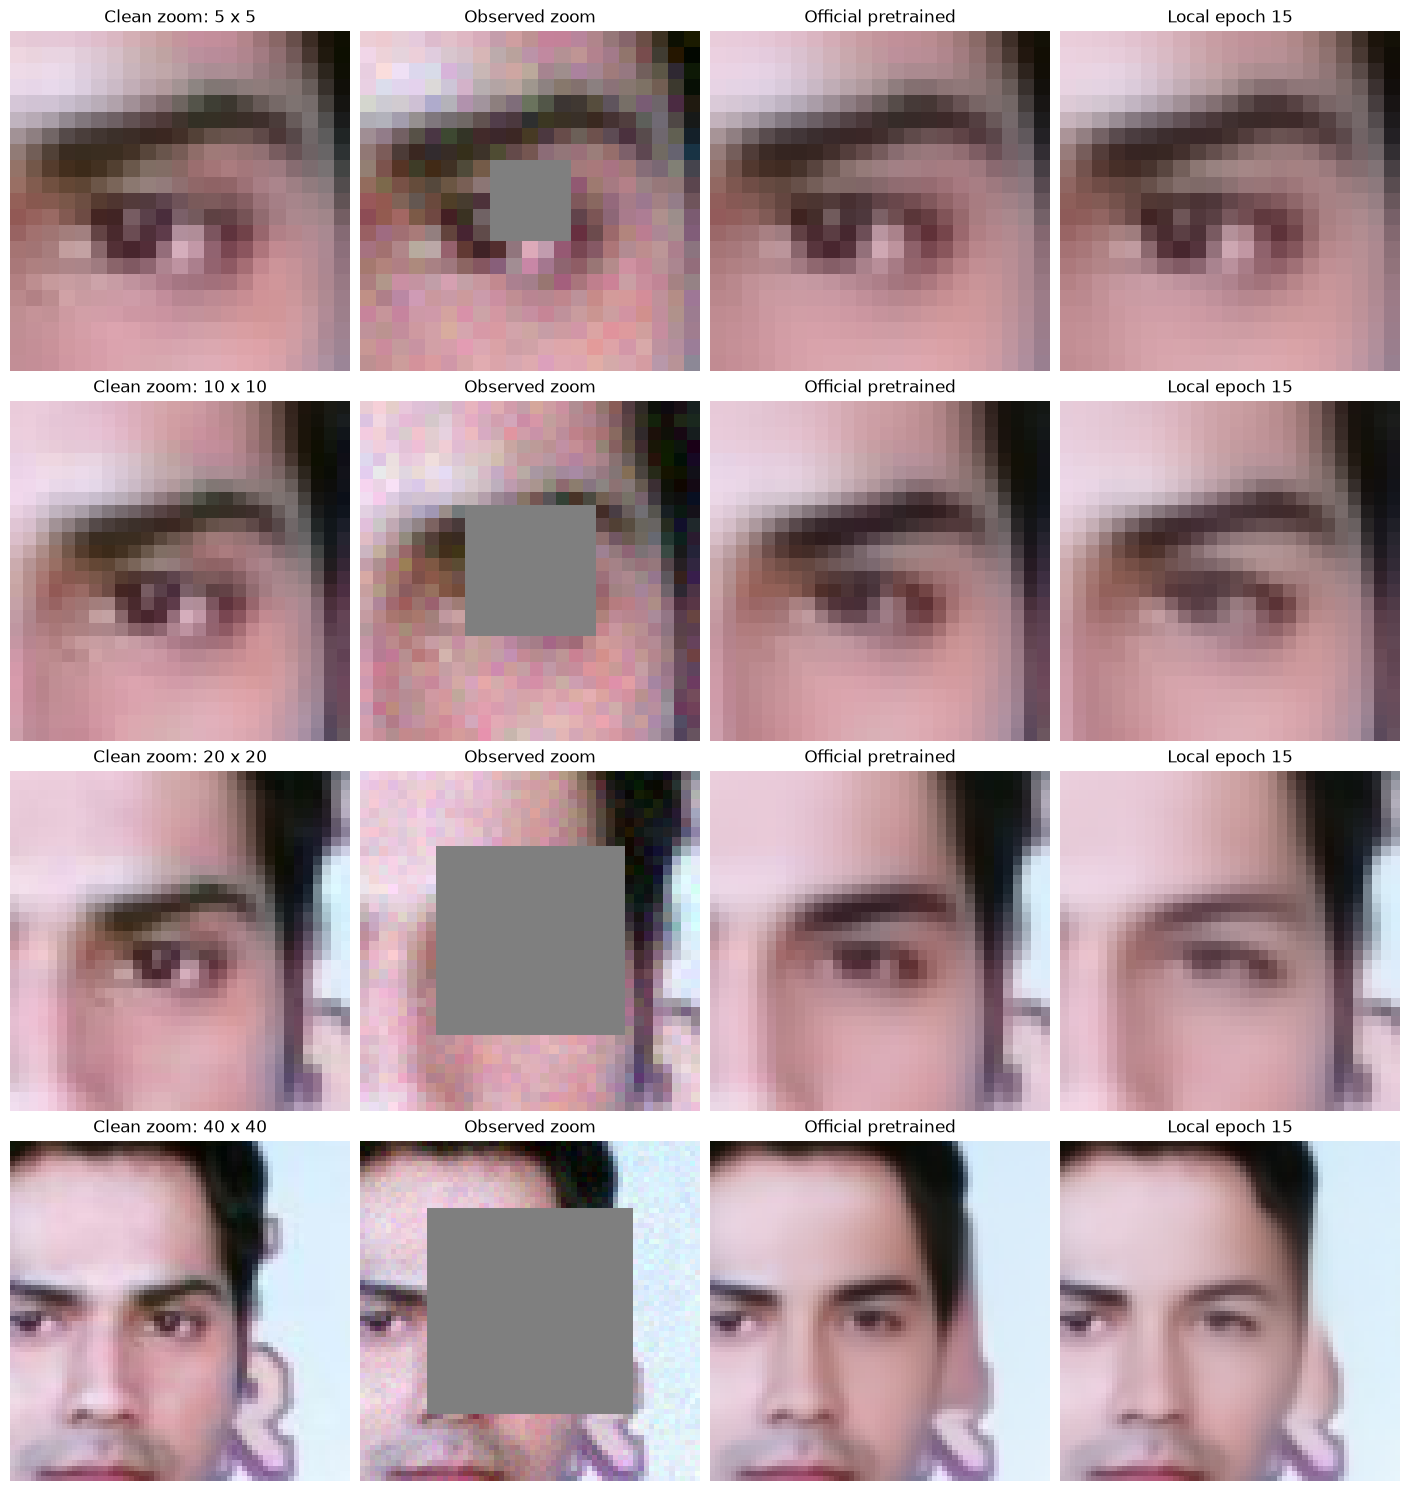

Saved: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/celeba/ot/pretrained_vs_local_epoch15_box_inpainting/182643/center_x80_y64/official_vs_local_epoch15_zoomed_regions.png


In [7]:
fig, axes = plt.subplots(len(MASK_SIZES), 4, figsize=(14, 3.7 * len(MASK_SIZES)), constrained_layout=True)
for row, size in enumerate(MASK_SIZES):
    item = results[size]
    top, left, bottom, right = item['bounds']
    margin = max(8, size // 3)
    y0, y1 = max(0, top - margin), min(MODEL_SIZE, bottom + margin)
    x0, x1 = max(0, left - margin), min(MODEL_SIZE, right + margin)
    target = np.s_[y0:y1, x0:x1]
    axes[row, 0].imshow(rgb_display(clean_np[:, target[0], target[1]])); axes[row, 0].set_title(f'Clean zoom: {size} x {size}')
    axes[row, 1].imshow(rgb_display(item['observed'][:, target[0], target[1]])); axes[row, 1].set_title('Observed zoom')
    axes[row, 2].imshow(rgb_display(item['official'][:, target[0], target[1]])); axes[row, 2].set_title('Official pretrained')
    axes[row, 3].imshow(rgb_display(item['local_epoch15'][:, target[0], target[1]])); axes[row, 3].set_title('Local epoch 15')
    for ax in axes[row]:
        ax.axis('off')
zoom_path = OUTPUT_DIR / 'official_vs_local_epoch15_zoomed_regions.png'
fig.savefig(zoom_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {zoom_path}')

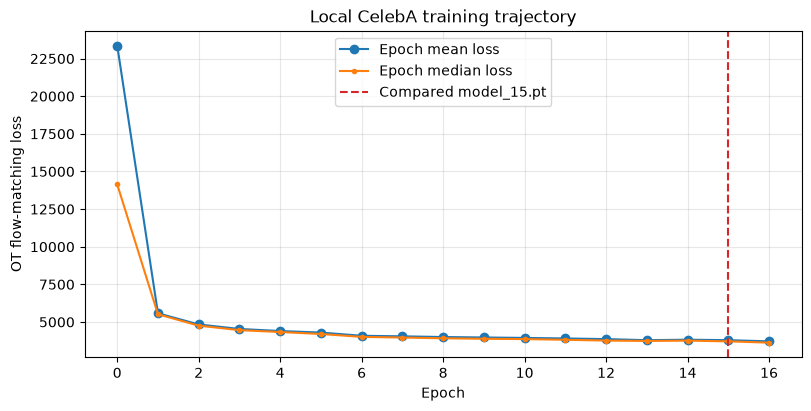

Loss log reaches epoch 16; model_15.pt is the latest completed periodic checkpoint.
Saved: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/celeba/ot/pretrained_vs_local_epoch15_box_inpainting/182643/center_x80_y64/local_training_loss_by_epoch.png


In [8]:
# Summarize the local run's training trajectory when its loss log is available.
if LOCAL_LOSS_PATH.is_file():
    pattern = re.compile(r'Epoch: (\d+), iter: (\d+), Loss: ([0-9.eE+-]+)')
    epoch_losses = {}
    for line in LOCAL_LOSS_PATH.read_text().splitlines():
        match = pattern.search(line)
        if match:
            epoch_losses.setdefault(int(match.group(1)), []).append(float(match.group(3)))
    epochs = sorted(epoch_losses)
    means = [float(np.mean(epoch_losses[epoch])) for epoch in epochs]
    medians = [float(np.median(epoch_losses[epoch])) for epoch in epochs]
    fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
    ax.plot(epochs, means, marker='o', label='Epoch mean loss')
    ax.plot(epochs, medians, marker='.', label='Epoch median loss')
    ax.axvline(15, color='tab:red', linestyle='--', label='Compared model_15.pt')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('OT flow-matching loss')
    ax.set_title('Local CelebA training trajectory')
    ax.grid(alpha=0.3); ax.legend()
    loss_path = OUTPUT_DIR / 'local_training_loss_by_epoch.png'
    fig.savefig(loss_path, dpi=180, bbox_inches='tight')
    plt.show()
    print(f'Loss log reaches epoch {max(epochs)}; model_15.pt is the latest completed periodic checkpoint.')
    print(f'Saved: {loss_path}')
else:
    print(f'Local loss log not found: {LOCAL_LOSS_PATH}')

## Interpretation

Compare missing-region PSNR and the zoomed regions rather than full-image PSNR alone. The official and local models use the same observation and stochastic solver draws for each mask size. Consequently, systematic differences mainly reflect the learned priors. Set `IMAGE_OVERRIDE`, `MASK_SIZES`, or `MASK_CENTER_XY` in the configuration cell to repeat the comparison elsewhere.